In [1]:
import pyphysics as phys
import numpy as np
import matplotlib.pyplot as plt
from collections import defaultdict
%matplotlib widget

In [ ]:
states = ["12+", "52+"]
erange = (0.5, 6, 0.025)
elevel = 3.5
wlevel = 50000
angles = [30, 45, 60, 90, 120, 150, 175]

res = defaultdict(list)
for state in states:
    inter = phys.AZUREInterface(f"./Inputs/in_{state}.azr")
    for angle in angles:
        inter.set_parameters(
            energy_range=erange,
            angle=angle,
            level_energy=elevel,
            level_width=wlevel,
        )
        inter.call_azure()
        # print(inter.azure.config.labels)
        inter.erase_copy()
        res[state].append(inter.results)

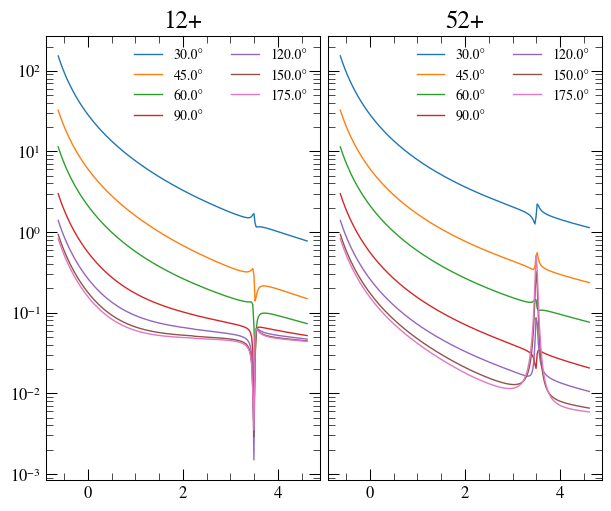

In [15]:
# Draw in single figures
fig, axs = plt.subplots(1, 2, constrained_layout=True, sharex=True, sharey=True, figsize=(6, 5))
for i, state in enumerate(states):
    ax = axs.flat[i]
    for j, angle in enumerate(angles):
        out = res[state][j]
        ax.set_yscale("log")
        ax.plot(out.e_x, out.xs_com_fit, label=f"{angle:.1f}°")
    ax.set_title(state)
    ax.legend(fontsize=10, ncol=2)

Text(0.5, 1.0, '5/2+ at 175.0°')

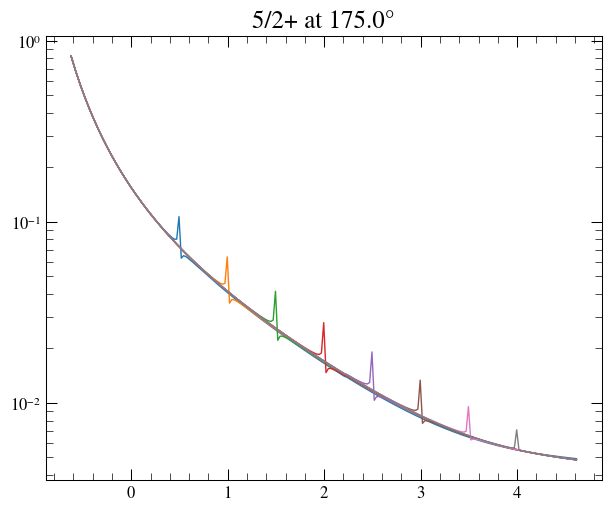

In [25]:
# Vary energy of 5/2+
width = 0.5e3
energies = np.arange(0.5, 4.5, 0.5)
angle = 175

rese = []
inter = phys.AZUREInterface(f"./Inputs/in_52+.azr")
for energy in energies:
    inter.set_parameters(
        energy_range=erange,
        angle=angle,
        level_energy=energy,  # type: ignore
        level_width=width,
    )
    inter.call_azure()
    inter.erase_copy()
    rese.append(inter.results)

fig, ax = plt.subplots(constrained_layout=True, figsize=(6, 5))
for i, energy in enumerate(energies):
    out = rese[i]
    ax.set_yscale("log")
    ax.plot(out.e_x, out.xs_com_fit, label=f"{energy:.1f} MeV")
ax.set_title(f"5/2+ at {angle:.1f}°")

Text(0.5, 1.0, '1/2+ at 175.0°')

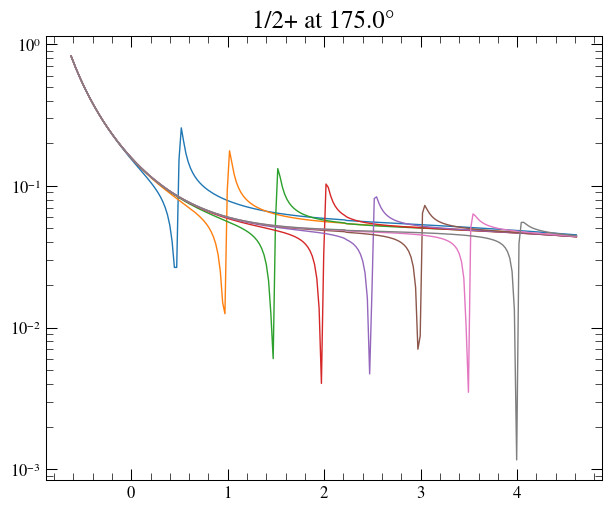

In [27]:
# Vary energy of 1/2+
width = 50e3
energies = np.arange(0.5, 4.5, 0.5)
angle = 175

rese = []
inter = phys.AZUREInterface(f"./Inputs/in_12+.azr")
for energy in energies:
    inter.set_parameters(
        energy_range=erange,
        angle=angle,
        level_energy=energy,  # type: ignore
        level_width=width,
    )
    inter.call_azure()
    inter.erase_copy()
    rese.append(inter.results)

fig, ax = plt.subplots(constrained_layout=True, figsize=(6, 5))
for i, energy in enumerate(energies):
    out = rese[i]
    ax.set_yscale("log")
    ax.plot(out.e_x, out.xs_com_fit, label=f"{energy:.1f} MeV")
ax.set_title(f"1/2+ at {angle:.1f}°")